# Feature Reduction 
## PCA (Principle component analysis)

##  t-SNE

In [1]:
import pandas as pd
import numpy as np
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = 'https://raw.githubusercontent.com/senihberkay/US-Army-ANSUR-II/master/ANSUR%20II%20FEMALE%20Public.csv'
df = pd.read_csv(url)
df.shape

(1986, 108)

In [3]:
df.to_csv('Ansur.csv')

In [4]:
df.columns[:10]

Index(['SubjectId', 'abdominalextensiondepthsitting', 'acromialheight',
       'acromionradialelength', 'anklecircumference', 'axillaheight',
       'balloffootcircumference', 'balloffootlength', 'biacromialbreadth',
       'bicepscircumferenceflexed'],
      dtype='object')

In [5]:
df.head()

,SubjectId,abdominalextensiondepthsitting,acromialheight,acromionradialelength,anklecircumference,axillaheight,balloffootcircumference,balloffootlength,biacromialbreadth,bicepscircumferenceflexed,...,Branch,PrimaryMOS,SubjectsBirthLocation,SubjectNumericRace,Ethnicity,DODRace,Age,Heightin,Weightlbs,WritingPreference
0,10037,231,1282,301,204,1180,222,177,373,315,...,Combat Support,92Y,Germany,2,NaN,2,26,61,142,Right hand
1,10038,194,1379,320,207,1292,225,178,372,272,...,Combat Service Support,25U,California,3,Mexican,3,21,64,120,Right hand
2,10042,183,1369,329,233,1271,237,196,397,300,...,Combat Service Support,35D,Texas,1,NaN,1,23,68,147,Right hand
3,10043,261,1356,306,214,1250,240,188,384,364,...,Combat Service Support,25U,District of Columbia,8,Caribbean Islander,2,22,66,175,Right hand
4,10051,309,1303,308,214,1210,217,182,378,320,...,Combat Arms,42A,Texas,1,NaN,1,45,63,195,Right hand


In [6]:
# select only numerical columns for t-SNE
features_df = df.select_dtypes(include = ['float64','int64'])

In [7]:
features_df.isnull().sum()

SubjectId                         0
abdominalextensiondepthsitting    0
acromialheight                    0
acromionradialelength             0
anklecircumference                0
                                 ..
SubjectNumericRace                0
DODRace                           0
Age                               0
Heightin                          0
Weightlbs                         0
Length: 99, dtype: int64

In [8]:
# Handle missing values
features_df = features_df.dropna()

In [9]:
# standardizing features
scalar = StandardScaler()
scaled_features = scalar.fit_transform(features_df)

In [10]:
len(scaled_features)

1986

In [11]:
scaled_features.shape

(1986, 99)

In [ ]:
# Apply t-SNE
tsne = TSNE(n_components=2, perplexity=30, max_iter=1000,random_state=42)
tsne_result = tsne.fit_transform(scaled_features)

In [ ]:
# to visulalize
tsne_df = pd.DataFrame(tsne_result, columns=['TSNE1','TSNE2'])

In [ ]:
tsne_df.shape

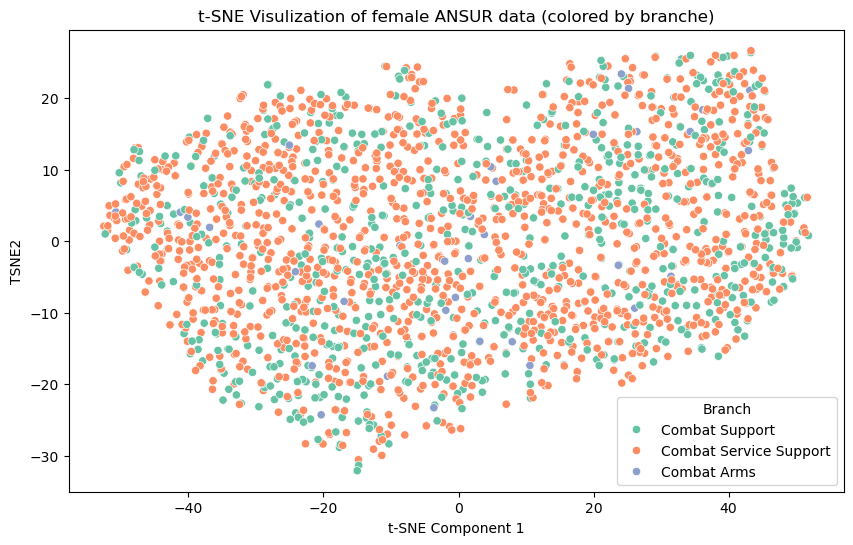

In [13]:
# visualization
if 'Branch' in df.columns:
    tsne_df['Branch'] = df.loc[features_df.index, 'Branch']
    plt.figure(figsize=(10,6))
    sns.scatterplot(data = tsne_df, x='TSNE1', y = 'TSNE2', hue= 'Branch', palette='Set2')
    plt.title('t-SNE Visulization of female ANSUR data (colored by branche)')
else:
    plt.figure(figsize=(10,6))
    sns.scatterplot(data = tsne_df, x='TSNE1', y = 'TSNE2', alpha =0.6)
    plt.title('t-SNE Visulization of female ANSUR data')
    
plt.xlabel('t-SNE Component 1')
plt.show()
    

C:\Users\Haier\AppData\Local\Temp\ipykernel_5384\3705987154.py:5: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(data = tsne_df, x='TSNE1', y = 'TSNE2', palette='Set2')


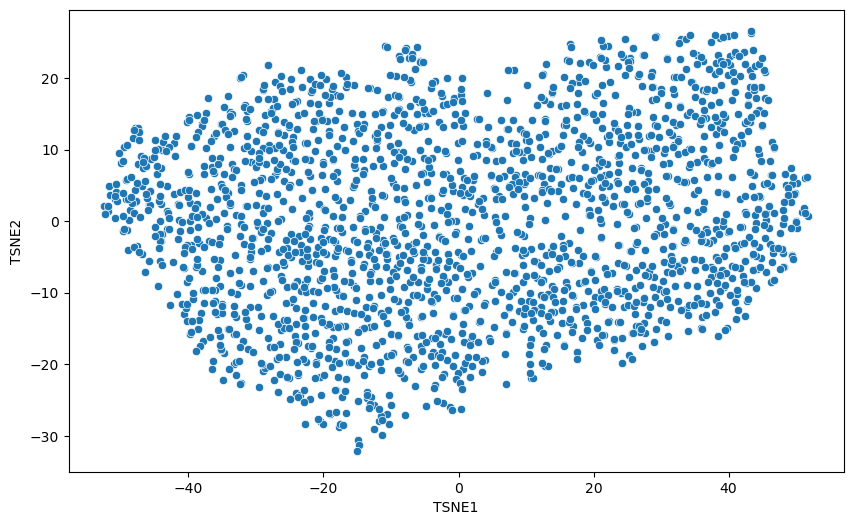

In [14]:
# visualization
if 'Branch' in df.columns:
    tsne_df['Branch'] = df.loc[features_df.index, 'Branch']
    plt.figure(figsize=(10,6))
    sns.scatterplot(data = tsne_df, x='TSNE1', y = 'TSNE2', palette='Set2')
else:
    plt.figure(figsize=(10,6))
    sns.scatterplot(data = tsne_df, x='TSNE1', y = 'TSNE2', alpha =0.6)
    

In [15]:
from sklearn.feature_selection import VarianceThreshold

# Apply variance threshod on numeric data
sel = VarianceThreshold(threshold=1.0)
sel.fit(features_df)

# Get boolean mask
mask = sel.get_support()
print(mask)


[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True False
  True  True  True]


In [16]:
# get name of selected features
selected_features = features_df.columns[mask]
print("selected features with variance > 1: ")
print(selected_features)

selected features with variance > 1: 
Index(['SubjectId', 'abdominalextensiondepthsitting', 'acromialheight',
       'acromionradialelength', 'anklecircumference', 'axillaheight',
       'balloffootcircumference', 'balloffootlength', 'biacromialbreadth',
       'bicepscircumferenceflexed', 'bicristalbreadth', 'bideltoidbreadth',
       'bimalleolarbreadth', 'bitragionchinarc', 'bitragionsubmandibulararc',
       'bizygomaticbreadth', 'buttockcircumference', 'buttockdepth',
       'buttockheight', 'buttockkneelength', 'buttockpopliteallength',
       'calfcircumference', 'cervicaleheight', 'chestbreadth',
       'chestcircumference', 'chestdepth', 'chestheight', 'crotchheight',
       'crotchlengthomphalion', 'crotchlengthposterioromphalion', 'earbreadth',
       'earlength', 'earprotrusion', 'elbowrestheight', 'eyeheightsitting',
       'footbreadthhorizontal', 'footlength', 'forearmcenterofgriplength',
       'forearmcircumferenceflexed', 'forearmforearmbreadth',
       'forearmhandle

In [17]:
reduced_df = features_df.loc[:,mask]
reduced_df.shape

(1986, 98)

In [18]:
# select only desired columns
weights_df = df[['Weightlbs', 'weightkg', 'Heightin']]

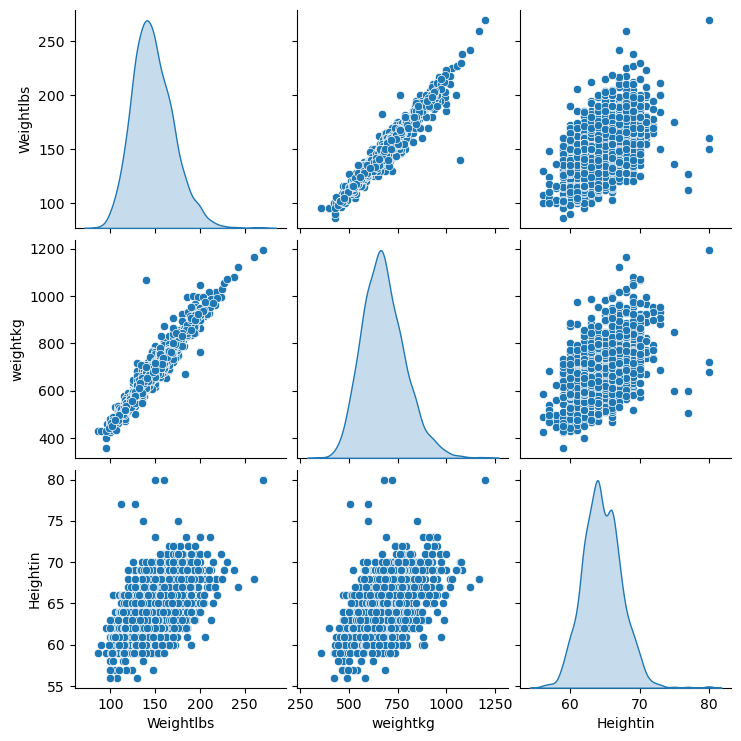

In [19]:
sns.pairplot(weights_df, diag_kind='kde')

In [20]:
weights_df.corr()

,Weightlbs,weightkg,Heightin
Weightlbs,1.000000,0.970784,0.502403
weightkg,0.970784,1.000000,0.502772
Heightin,0.502403,0.502772,1.000000


<Axes: >

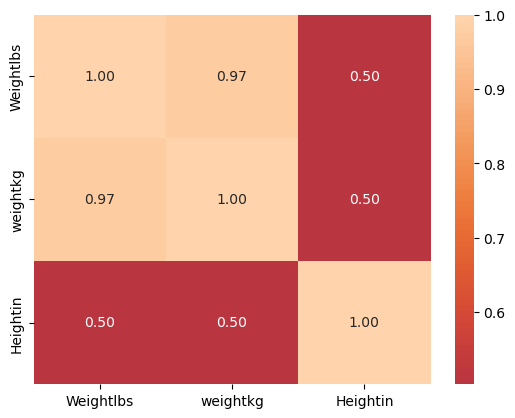

In [21]:
sns.heatmap(weights_df.corr(),annot=True,center=0, fmt='.2f')

In [22]:
weights_df.head()

,Weightlbs,weightkg,Heightin
0,142,657,61
1,120,534,64
2,147,663,68
3,175,782,66
4,195,886,63


In [23]:
df.columns

Index(['SubjectId', 'abdominalextensiondepthsitting', 'acromialheight',
       'acromionradialelength', 'anklecircumference', 'axillaheight',
       'balloffootcircumference', 'balloffootlength', 'biacromialbreadth',
       'bicepscircumferenceflexed',
       ...
       'Branch', 'PrimaryMOS', 'SubjectsBirthLocation', 'SubjectNumericRace',
       'Ethnicity', 'DODRace', 'Age', 'Heightin', 'Weightlbs',
       'WritingPreference'],
      dtype='object', length=108)

In [24]:
df['Height m'] = df['Heightin']/39.37
df['BMI'] = df['weightkg']/df['Height m']**2

In [25]:
df['BMI'].head()

0    273.675884
1    202.074791
2    222.242203
3    278.259315
4    346.005859
Name: BMI, dtype: float64

In [26]:
df['Height m'].head()

0    1.549403
1    1.625603
2    1.727203
3    1.676403
4    1.600203
Name: Height m, dtype: float64